# Задания 10–11. Набор URL и модель опасных ссылок

Набор: PhiUSIIL Phishing URL Dataset (UCI). Подготовка выполняется скриптом `python -m ml.data.prepare_urls`, отчёт о шагах очистки — `docs/10_url_dataset_report.md`.

In [1]:
# Настройка путей. Работает локально и в Google Colab.
import sys
import zipfile
from pathlib import Path

if "google.colab" in sys.modules and not Path("ml").exists():
    # В Colab загрузите архив проекта sms_guard.zip (см. README).
    from google.colab import files
    uploaded = files.upload()
    zipfile.ZipFile(next(iter(uploaded))).extractall(".")

ROOT = Path.cwd() if (Path.cwd() / "ml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print("Корень проекта:", ROOT.name)

Корень проекта: AIproject


In [2]:
import json
import os
import time
from datetime import date

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, f1_score, fbeta_score, make_scorer, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from ml.url_features import FEATURE_TITLES, MODEL_FEATURES, model_features

os.environ["PYTHONPATH"] = str(ROOT)
data = pd.read_parquet(ROOT / "data" / "processed" / "url_features.parquet")
train, val, test = (data[data["split"] == name] for name in ("train", "val", "test"))
X_train, y_train = train[MODEL_FEATURES].to_numpy(float), train["label"].to_numpy()
X_val, y_val = val[MODEL_FEATURES].to_numpy(float), val["label"].to_numpy()
print({name: len(part) for name, part in [("train", train), ("val", val), ("test", test)]})
print("Общих доменов train/test:", len(set(train.domain_group) & set(test.domain_group)))

{'train': 71341, 'val': 14804, 'test': 13855}
Общих доменов train/test: 0


## Задание 10. Паспорт и устранение артефактов разметки

| Пункт | Значение |
|---|---|
| Источник | UCI Machine Learning Repository, PhiUSIIL Phishing URL Dataset |
| Ссылка | archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset |
| Лицензия | CC BY 4.0 |
| Дата загрузки | 13.11.2026 |
| Объём | 235 795 URL (проверено) |
| Метки | В источнике 1 — легитимный, 0 — фишинг; приведены к 0 — безопасный, 1 — фишинг |
| Ограничения | Безопасные адреса — только главные страницы популярных сайтов; готовые признаки набора получены при загрузке страниц, поэтому не используются |

**Артефакт разметки.** Все безопасные адреса записаны как `https://www.домен` без пути, а у фишинговых путь есть примерно в 60 % случаев. Модель, обученная на полном адресе, выучила бы правило «есть путь — значит фишинг» и ошибалась бы на любой нормальной ссылке вроде `https://www.example.com/about`. Поэтому модель получает только домен: адрес приводится к виду `http://домен`, а признаки схемы, пути, параметров и символа `@` в модель не входят. Они остаются в объяснении результата и в правилах риска.

После приведения одинаковые домены считаются дубликатами; домены, встречающиеся с обеими метками, удалены. Из 219 040 уникальных доменов взята стратифицированная подвыборка в 100 000. Разбиение 70/15/15 выполнено `GroupShuffleSplit` по регистрируемому домену.

In [3]:
print("Доля фишинга:", data["label"].mean().round(4))
KEY = ["host_length", "subdomain_count", "hyphen_count", "host_digit_ratio", "host_entropy", "suspicious_word_count"]
means = data.groupby("label")[KEY].mean().T
means.columns = ["Безопасные", "Фишинг"]
means.index = [FEATURE_TITLES[k] for k in KEY]
means.round(3)

Доля фишинга: 0.3846


,Безопасные,Фишинг
Длина домена,15.238,23.304
Число поддоменов,0.031,0.721
Дефисы в домене,0.082,0.566
Доля цифр в домене,0.004,0.072
Энтропия домена,3.305,3.608
Подозрительные слова,0.007,0.045


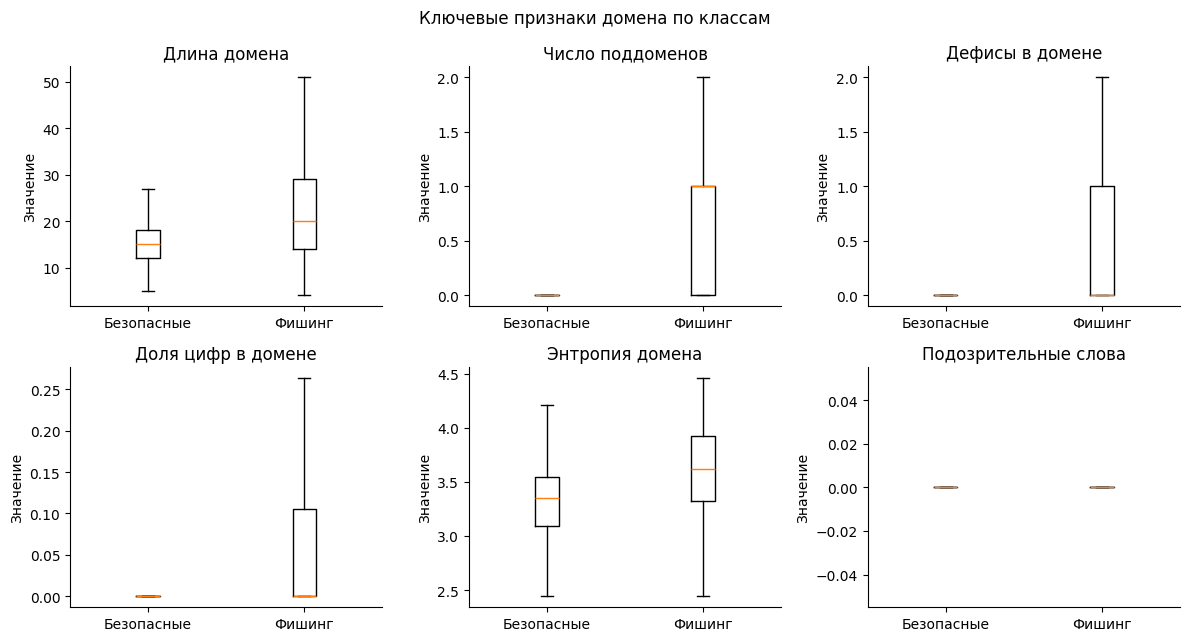

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, key in zip(axes.ravel(), KEY):
    groups = [data.loc[data["label"] == label, key].clip(upper=data[key].quantile(0.99)) for label in (0, 1)]
    ax.boxplot(groups, tick_labels=["Безопасные", "Фишинг"], showfliers=False)
    ax.set_title(FEATURE_TITLES[key])
    ax.set_ylabel("Значение")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Ключевые признаки домена по классам")
fig.tight_layout()
fig.savefig(FIGURES / "url_eda_boxplots.png", dpi=130)
plt.show()

### Почему модель не получает полный адрес

Для сравнения обучим ту же модель на признаках полного адреса (со схемой и путём). Высокое качество здесь достигается за счёт артефакта разметки, а не за счёт настоящих признаков фишинга.

In [5]:
from ml.url_features import FEATURE_NAMES, extract_url_features

subset = pd.concat([train.sample(20000, random_state=1), val.sample(5000, random_state=1)])
full = pd.DataFrame([extract_url_features(u) for u in subset["url"]], index=subset.index)[FEATURE_NAMES]
is_train = subset["split"] == "train"
artifact_model = HistGradientBoostingClassifier(random_state=42).fit(full[is_train], subset.loc[is_train, "label"])
artifact_auc = roc_auc_score(subset.loc[~is_train, "label"], artifact_model.predict_proba(full[~is_train])[:, 1])
print(f"ROC-AUC модели на полном адресе: {artifact_auc:.4f}")
example = pd.DataFrame([extract_url_features("https://www.example.com/about")])[FEATURE_NAMES]
print(f"Её оценка для https://www.example.com/about: {artifact_model.predict_proba(example)[0, 1]:.3f}")

ROC-AUC модели на полном адресе: 0.9999
Её оценка для https://www.example.com/about: 1.000


## Задание 11. Подбор гиперпараметров

Кросс-валидация на обучающей выборке по группам доменов (`GroupKFold`, 3 фолда), метрика F2.

In [6]:
CV = GroupKFold(n_splits=3)
F2 = make_scorer(fbeta_score, beta=2)
CANDIDATES = {
    "Logistic Regression": (
        Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        {"clf__C": [0.1, 1, 10]},
    ),
    "Random Forest": (
        Pipeline([("clf", RandomForestClassifier(class_weight="balanced_subsample", random_state=42, n_jobs=1))]),
        {"clf__n_estimators": [200], "clf__max_depth": [12, 24], "clf__min_samples_leaf": [1, 5]},
    ),
    "Gradient Boosting": (
        Pipeline([("clf", HistGradientBoostingClassifier(random_state=42, class_weight="balanced"))]),
        {"clf__learning_rate": [0.05, 0.1], "clf__max_leaf_nodes": [31, 63]},
    ),
}
searches = {}
for name, (model, grid) in CANDIDATES.items():
    started = time.perf_counter()
    search = GridSearchCV(model, grid, scoring=F2, cv=CV, n_jobs=4)
    search.fit(X_train, y_train, groups=train["domain_group"].to_numpy())
    searches[name] = search
    print(f"{name}: {search.best_params_}, F2 (CV) = {search.best_score_:.4f}, {time.perf_counter() - started:.0f} с")

Logistic Regression: {'clf__C': 10}, F2 (CV) = 0.7216, 4 с


Random Forest: {'clf__max_depth': 24, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}, F2 (CV) = 0.7373, 45 с


Gradient Boosting: {'clf__learning_rate': 0.1, 'clf__max_leaf_nodes': 31}, F2 (CV) = 0.7388, 7 с


## Сравнение на валидационной выборке

In [7]:
def metrics(y, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred), "Recall": recall_score(y, pred),
        "F1": f1_score(y, pred), "F2": fbeta_score(y, pred, beta=2),
        "ROC-AUC": roc_auc_score(y, proba), "PR-AUC": average_precision_score(y, proba),
    }

rows, val_proba = {}, {}
for name, search in searches.items():
    model = search.best_estimator_
    started = time.perf_counter()
    val_proba[name] = model.predict_proba(X_val)[:, 1]
    per_url_ms = (time.perf_counter() - started) / len(X_val) * 1000
    rows[name] = {**metrics(y_val, val_proba[name]), "Мс на 1 URL": per_url_ms}
pd.DataFrame(rows).T.round(4)

,Accuracy,Precision,Recall,F1,F2,ROC-AUC,PR-AUC,Мс на 1 URL
Logistic Regression,0.8346,0.8784,0.6562,0.7512,0.6912,0.8387,0.8475,0.0002
Random Forest,0.8477,0.9070,0.6683,0.7695,0.7054,0.8530,0.8595,0.0170
Gradient Boosting,0.8449,0.8962,0.6700,0.7668,0.7057,0.8559,0.8612,0.0020


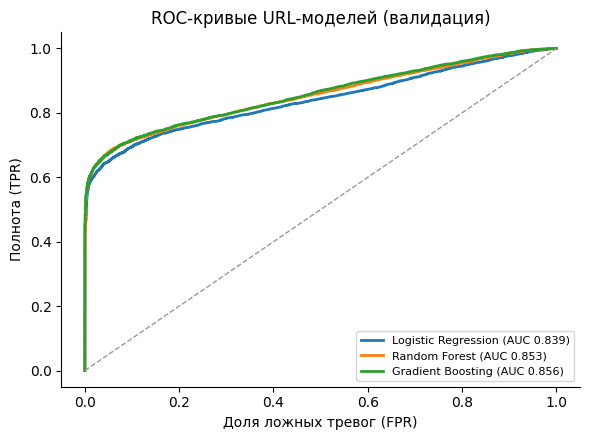

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for name, proba in val_proba.items():
    fpr, tpr, _ = roc_curve(y_val, proba)
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC {roc_auc_score(y_val, proba):.3f})")
ax.plot([0, 1], [0, 1], color="#999999", lw=1, ls="--")
ax.set(title="ROC-кривые URL-моделей (валидация)", xlabel="Доля ложных тревог (FPR)", ylabel="Полнота (TPR)")
ax.legend(loc="lower right", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "url_roc.png", dpi=130)
plt.show()

## Важность признаков

Коэффициенты Logistic Regression (после масштабирования):
Бесплатный хостинг              2.238
Число поддоменов                1.593
Цифры в URL                     1.112
Подозрительная доменная зона    1.104
Самая длинная часть домена     -0.629
Длина URL                       0.559
Длина домена                    0.559
Число точек                    -0.501
Доля цифр в домене              0.263
IP-адрес вместо домена          0.241


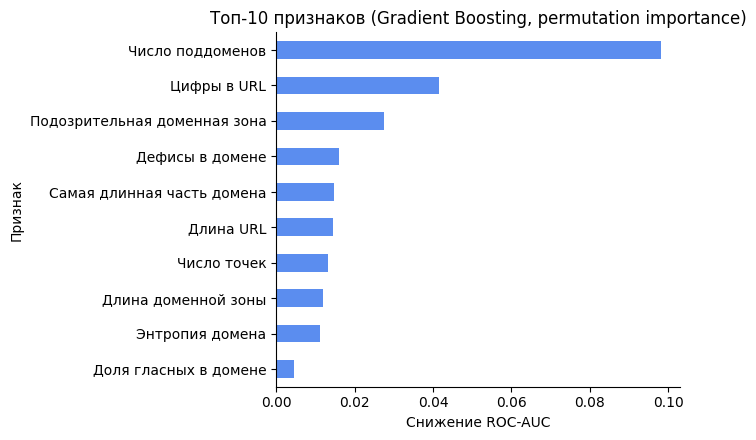

In [9]:
lr = searches["Logistic Regression"].best_estimator_.named_steps["clf"]
coef = pd.Series(lr.coef_[0], index=[FEATURE_TITLES[k] for k in MODEL_FEATURES]).sort_values(key=abs, ascending=False)
print("Коэффициенты Logistic Regression (после масштабирования):")
print(coef.head(10).round(3).to_string())

best_tree = max(["Random Forest", "Gradient Boosting"], key=lambda n: searches[n].best_score_)
sample = val.sample(4000, random_state=42)
perm = permutation_importance(searches[best_tree].best_estimator_, sample[MODEL_FEATURES].to_numpy(float), sample["label"],
                              scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=1)
importance = pd.Series(perm.importances_mean, index=[FEATURE_TITLES[k] for k in MODEL_FEATURES]).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
importance.tail(10).plot.barh(ax=ax, color="#5b8def")
ax.set(title=f"Топ-10 признаков ({best_tree}, permutation importance)", xlabel="Снижение ROC-AUC", ylabel="Признак")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "url_feature_importance.png", dpi=130)
plt.show()

## Пороги категорий на валидации

- `t2` (DANGEROUS): порог с максимальным F2 при Precision ≥ 0,85 — уверенное срабатывание.
- `t1` (SUSPICIOUS): минимальный порог, при котором Precision ≥ 0,75, то есть хотя бы три из четырёх таких ссылок действительно фишинговые. Порог по Recall ≥ 0,95 оказался около 0,20 и отмечал как подозрительные даже google.com и kaspi.kz, потому что у обычных сайтов P_url в среднем около 0,23.

In [10]:
best_name = max(searches, key=lambda n: fbeta_score(y_val, (val_proba[n] >= 0.5).astype(int), beta=2))
proba = val_proba[best_name]
precision, recall, thresholds = precision_recall_curve(y_val, proba)
precision, recall = precision[:-1], recall[:-1]
f2 = 5 * precision * recall / np.maximum(4 * precision + recall, 1e-9)
f2[precision < 0.85] = -1
T2 = round(float(thresholds[int(np.argmax(f2))]), 4)
T1 = round(float(thresholds[np.where(precision >= 0.75)[0][0]]), 4)
T1 = min(T1, T2)
print("Выбрана модель:", best_name, "| t1 =", T1, "| t2 =", T2)
pd.DataFrame({
    "t1 (подозрительно)": metrics(y_val, proba, T1),
    "t2 (опасно)": metrics(y_val, proba, T2),
}).T.round(4)

Выбрана модель: Gradient Boosting | t1 = 0.2871 | t2 = 0.3978


,Accuracy,Precision,Recall,F1,F2,ROC-AUC,PR-AUC
t1 (подозрительно),0.8078,0.7498,0.7430,0.7464,0.7443,0.8559,0.8612
t2 (опасно),0.8391,0.8501,0.7007,0.7682,0.7263,0.8559,0.8612


## Однократная оценка на тесте и сохранение

In [11]:
final = searches[best_name].best_estimator_
X_test, y_test = test[MODEL_FEATURES].to_numpy(float), test["label"].to_numpy()
test_proba = final.predict_proba(X_test)[:, 1]
test_metrics = metrics(y_test, test_proba, T2)
ARTIFACTS = ROOT / "ml" / "artifacts"
joblib.dump(final, ARTIFACTS / "url_model.joblib", compress=3)
meta = {
    "version": "1.0.0",
    "algorithm": best_name,
    "params": {k: str(v) for k, v in searches[best_name].best_params_.items()},
    "features": MODEL_FEATURES,
    "t1": T1,
    "t2": T2,
    "metrics_test": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "dataset": "PhiUSIIL (UCI), домены, 100 000 записей",
    "trained_at": date.today().isoformat(),
}
(ARTIFACTS / "url_model_meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Размер файла, МБ: {(ARTIFACTS / 'url_model.joblib').stat().st_size / 1024 ** 2:.2f}")
pd.Series(test_metrics).round(4).to_frame("Тест, класс фишинг (порог t2)")

Размер файла, МБ: 0.15


,"Тест, класс фишинг (порог t2)"
Accuracy,0.8345
Precision,0.8071
Recall,0.6611
F1,0.7269
F2,0.6859
ROC-AUC,0.8342
PR-AUC,0.8191


## Проверка на 20 искусственных URL

In [12]:
ARTIFICIAL = [
    ("https://www.google.com", 0), ("https://kaspi.kz/shop", 0), ("https://halykbank.kz", 0),
    ("https://egov.kz/cms/ru", 0), ("https://www.wikipedia.org/wiki/Phishing", 0), ("https://github.com/django", 0),
    ("https://www.microsoft.com/ru-ru", 0), ("https://www.apple.com/iphone", 0), ("https://telegram.org/apps", 0),
    ("https://www.amazon.com/gp/cart", 0),
    ("http://secure-bank-verify.example/login", 1), ("http://192.0.2.15/account-update", 1),
    ("http://xn--exmple-cua.test/secure/login?verify=1", 1), ("http://kaspi-bonus-prize.test/claim", 1),
    ("http://login.halyk-secure-update.example/verify", 1), ("http://paypa1-account.example/confirm", 1),
    ("http://free-gift-winner.top/claim", 1), ("http://bank-kz-verify.test", 1),
    ("http://account-verify.update-secure.login.example", 1), ("http://g00gle-support.example/password", 1),
]
t = pd.DataFrame(ARTIFICIAL, columns=["URL", "Ожидание"])
t["P_url"] = [final.predict_proba(np.array([[model_features(u)[k] for k in MODEL_FEATURES]], float))[0, 1] for u in t["URL"]]
t["Категория"] = np.select([t["P_url"] >= T2, t["P_url"] >= T1], ["DANGEROUS", "SUSPICIOUS"], "SAFE")
t["Ожидание"] = t["Ожидание"].map({0: "безопасная", 1: "подозрительная"})
t.round(3)

,URL,Ожидание,P_url,Категория
0,https://www.google.com,безопасная,0.228,SAFE
1,https://kaspi.kz/shop,безопасная,0.252,SAFE
2,https://halykbank.kz,безопасная,0.374,SUSPICIOUS
3,https://egov.kz/cms/ru,безопасная,0.254,SAFE
4,https://www.wikipedia.org/wiki/Phishing,безопасная,0.232,SAFE
5,https://github.com/django,безопасная,0.233,SAFE
6,https://www.microsoft.com/ru-ru,безопасная,0.231,SAFE
7,https://www.apple.com/iphone,безопасная,0.192,SAFE
8,https://telegram.org/apps,безопасная,0.234,SAFE
9,https://www.amazon.com/gp/cart,безопасная,0.235,SAFE
